In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("loan_approval.csv")
df.head()

,income,credit_score,loan_amount,years_working,employment,loan_status
0,1320000,525,890000,11.0,Salaried,Rejected
1,1890000,749,400000,13.0,Self-employed,Approved
2,"13,80,000",622,390000,19.0,Salaried,Approved
3,1170000,530,910000,9.0,Self-employed,Rejected
4,690000,801,170000,0.0,Salaried,Approved


In [3]:
print(df.shape)
print(df.isnull().sum())
print("Duplicate Rows", df.duplicated().sum())
print(df.dtypes)

(152, 6)
income           0
credit_score     0
loan_amount      0
years_working    2
employment       0
loan_status      0
dtype: int64
Duplicate Rows 2
income               str
credit_score       int64
loan_amount        int64
years_working    float64
employment           str
loan_status          str
dtype: object


In [4]:
print(df["employment"].value_counts())
print()
print(df["loan_status"].value_counts())

employment
Salaried         83
Self-employed    65
salaried          1
Self Employed     1
SALARIED          1
self-employed     1
Name: count, dtype: int64

loan_status
Rejected     77
Approved     72
approved      1
Rejected      1
REJECTED      1
Name: count, dtype: int64


In [5]:
df.describe().round(2)

,credit_score,loan_amount,years_working
count,152.00,152.00,150.00
mean,682.70,737500.00,9.39
std,398.28,460761.32,6.07
min,451.00,50000.00,0.00
25%,556.50,300000.00,4.00
50%,640.50,705000.00,9.00
75%,779.25,1187500.00,15.00
max,5330.00,1500000.00,20.00


In [6]:
df = df.drop_duplicates()
print(df.shape)

(150, 6)


In [7]:
df["income"]=df["income"].str.replace(",","")
df["income"]=pd.to_numeric(df["income"])
print(df["income"].dtype)

int64


In [8]:
df[df["credit_score"] > 900]

,income,credit_score,loan_amount,years_working,employment,loan_status
40,1770000,5330,1140000,16.0,Self-employed,Rejected


In [9]:
df.loc[df["credit_score"] > 900, "credit_score"] = None
print(df["credit_score"].max())

845.0


In [10]:
credit_median = df["credit_score"].median()
years_median = df["years_working"].median()
df["credit_score"]=df["credit_score"].fillna(credit_median)
df["years_working"]=df["years_working"].fillna(years_median)
print("Median credit Score :",credit_median)
print("Median years working  :",years_median)
print("Median value left :",df .isnull().sum().sum())

Median credit Score : 646.0
Median years working  : 9.0
Median value left : 0


In [11]:
df ["employment"]=df ["employment"].str.strip()
df ["employment"]=df ["employment"].str.capitalize()
df ["employment"]=df ["employment"].replace("Self employed","Self-employed")
print(df["employment"].value_counts())

employment
Salaried         83
Self-employed    67
Name: count, dtype: int64


In [12]:
df["employment"] = df["employment"].map({"Salaried": 1, "Self-employed": 0})
print(df["employment"].value_counts())

employment
1    83
0    67
Name: count, dtype: int64


In [13]:
df["loan_status"]=df["loan_status"].str.strip()
df["loan_status"]=df["loan_status"].str.capitalize()
print(df["loan_status"].value_counts())

loan_status
Rejected    78
Approved    72
Name: count, dtype: int64


In [14]:
#df.groupby("loan_status").mean().round(2)
df.select_dtypes(include="number").groupby(df["loan_status"]).mean().round(2)

,income,credit_score,loan_amount,years_working,employment
loan_status,,,,,
Approved,1342638.89,724.94,582500.00,9.79,0.58
Rejected,1083461.54,586.73,888717.95,9.17,0.53


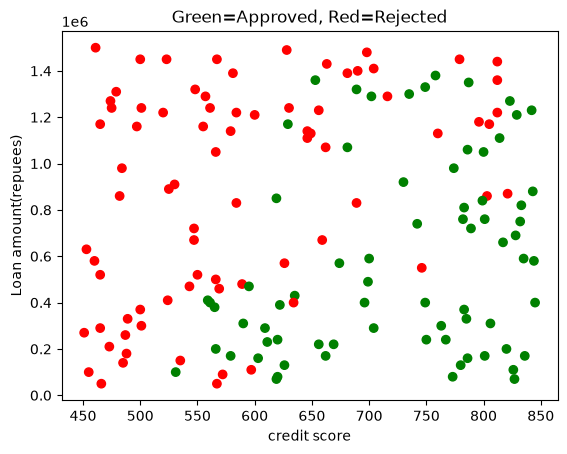

In [15]:
colours=df["loan_status"].map({"Approved": "green","Rejected":"red"})
plt.scatter(df["credit_score"],df["loan_amount"],c=colours)
plt.xlabel("credit score")
plt.ylabel("Loan amount(repuees)")
plt.title("Green=Approved, Red=Rejected")
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x = df.drop(columns=["loan_status"])
y = df["loan_status"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print(x_train_scaled.shape)
print(x_test_scaled.shape)

(120, 5)
(30, 5)


In [17]:
from sklearn.svm import SVC
model=SVC(kernel="rbf",C=1)
model.fit(x_train_scaled,y_train)
print("Model is trained")
print("Support Vector Class:",model.n_support_)# How many Support Vector each class have.{_}-> at the end means "learning during fit"

Model is trained
Support Vector Class: [32 34]


In [18]:
from sklearn.metrics import accuracy_score
y_pred=model.predict(x_test_scaled)
train_pred=model.predict(x_train_scaled)
print("Train accuracy :",round(accuracy_score(y_train,train_pred),3))
print("Test Accuracy :",round(accuracy_score(y_test,y_pred),3))

Train accuracy : 0.908
Test Accuracy : 0.933


In [19]:
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test,y_pred)

cm_table= pd.DataFrame(cm,index=model.classes_,columns=model.classes_)

cm_table


,Approved,Rejected
Approved,13,1
Rejected,1,15


In [20]:
new_person=pd.DataFrame({
    "income":[800000],
    "credit_score":[760],
    "loan_amount":[300000],
    "years_working":[6],
    "employment":[1]
})
new_scaled=scaler.transform(new_person)
print("Decision :",model.predict(new_scaled)[0])

Decision : Approved
